In [1]:
import kagglehub

path = kagglehub.dataset_download("garymk/kitti-3d-object-detection-dataset")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/garymk/kitti-3d-object-detection-dataset


In [2]:
from pathlib import Path
import kagglehub

path = Path(kagglehub.dataset_download("garymk/kitti-3d-object-detection-dataset"))
ROOT = next(path.rglob("label_2")).parent 

print("Training data:", ROOT)
for sub in ["velodyne", "label_2", "calib", "image_2"]:
    print(f"{sub:10s}", len(list((ROOT / sub).iterdir())), "files")

Training data: /kaggle/input/datasets/garymk/kitti-3d-object-detection-dataset/training
velodyne   7481 files
label_2    7481 files
calib      7481 files
image_2    7481 files


In [3]:
import numpy as np
import matplotlib.pyplot as plt

In [4]:
def load_scan(frame: str) -> np.ndarray:
    """(N, 4) array: x forward, y left, z up, intensity."""
    return np.fromfile(ROOT / "velodyne" / f"{frame}.bin", dtype=np.float32).reshape(-1, 4)

points = load_scan("000010")
print(points.shape)
print("x range:", points[:, 0].min().round(1), "to", points[:, 0].max().round(1))
print("z range:", points[:, 2].min().round(1), "to", points[:, 2].max().round(1))

(115875, 4)
x range: -60.4 to 78.4
z range: -14.1 to 2.9


In [5]:
z = points[:, 2]
print("1% lowest z:", np.percentile(z, 1).round(2))
print("points below -3 m:", (z < -3).sum())

1% lowest z: -1.97
points below -3 m: 16


In [6]:
def load_cam_to_velo(frame: str) -> np.ndarray:
    """4x4 transform from rectified camera coordinates to LiDAR coordinates."""
    calib = {}
    for line in (ROOT / "calib" / f"{frame}.txt").read_text().splitlines():
        if ":" in line:
            key, values = line.split(":", 1)
            calib[key] = np.array(values.split(), dtype=np.float64)
    r0 = np.eye(4)
    r0[:3, :3] = calib["R0_rect"].reshape(3, 3)
    tr = np.eye(4)
    tr[:3, :] = calib["Tr_velo_to_cam"].reshape(3, 4)
    return np.linalg.inv(r0 @ tr)

cam_to_velo = load_cam_to_velo("000010")
print(cam_to_velo.round(3))

[[ 0.     0.01   1.     0.273]
 [-1.     0.011  0.    -0.002]
 [-0.011 -1.     0.01  -0.072]
 [ 0.     0.     0.     1.   ]]


In [7]:
def load_labels(frame: str, cam_to_velo: np.ndarray) -> list[dict]:
    """Objects with centre, size (l, w, h) and yaw in LiDAR coordinates."""
    objects = []
    for line in (ROOT / "label_2" / f"{frame}.txt").read_text().splitlines():
        f = line.split()
        if f[0] == "DontCare":
            continue
        h, w, l, x, y, z, ry = map(float, f[8:15])
        centre = cam_to_velo @ np.array([x, y - h / 2, z, 1.0])  # camera y points down
        objects.append({"cls": f[0], "centre": centre[:3], "size": (l, w, h), "yaw": -ry - np.pi / 2})
    return objects

objects = load_labels("000010", cam_to_velo)
for o in objects:
    print(f"{o['cls']:12s} centre={o['centre'].round(1)}  size={np.round(o['size'], 1)}")

Car          centre=[ 5.5 -4.4 -0.9]  size=[3.4 1.6 1.6]
Car          centre=[12.1  2.4 -0.9]  size=[4.  1.7 1.4]
Pedestrian   centre=[23.8 -8.3 -0.5]  size=[1.1 0.7 2. ]
Car          centre=[16.8 -5.8 -0.8]  size=[3.2 1.6 1.5]
Car          centre=[22.3 -6.9 -0.8]  size=[4.1 1.7 1.4]
Car          centre=[23.9  0.4 -0.8]  size=[3.8 1.7 1.5]
Car          centre=[29.4 -0.6 -0.8]  size=[3.4 1.5 1.5]
Car          centre=[28.8 -7.9 -0.8]  size=[4.4 1.6 1.5]
Car          centre=[43.1 -4.5 -0.7]  size=[3.5 1.4 1.6]


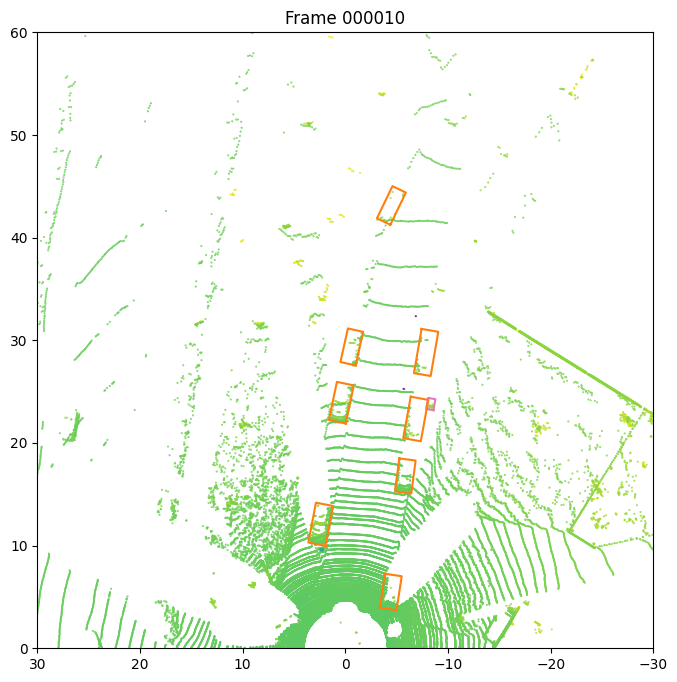

In [8]:
COLOURS = {"Car": "tab:orange", "Van": "tab:orange", "Pedestrian": "tab:pink", "Cyclist": "tab:green"}

def bev_corners(obj: dict) -> np.ndarray:
    l, w, _ = obj["size"]
    c, s = np.cos(obj["yaw"]), np.sin(obj["yaw"])
    local = np.array([[l/2, w/2], [l/2, -w/2], [-l/2, -w/2], [-l/2, w/2]])
    return local @ np.array([[c, -s], [s, c]]).T + obj["centre"][:2]

def plot_bev(frame: str, ax=None):
    points = load_scan(frame)
    objects = load_labels(frame, load_cam_to_velo(frame))
    keep = (points[:, 0] > 0) & (points[:, 0] < 60) & (np.abs(points[:, 1]) < 30)
    ax = ax or plt.subplots(figsize=(8, 8))[1]
    ax.scatter(points[keep, 1], points[keep, 0], s=0.2, c=points[keep, 2], cmap="viridis")
    for obj in objects:
        poly = np.vstack([bev_corners(obj), bev_corners(obj)[:1]])
        ax.plot(poly[:, 1], poly[:, 0], color=COLOURS.get(obj["cls"], "tab:red"), lw=1.5)
    ax.set(xlim=(30, -30), ylim=(0, 60), aspect="equal", title=f"Frame {frame}")
    return ax

plot_bev("000010")
plt.show()

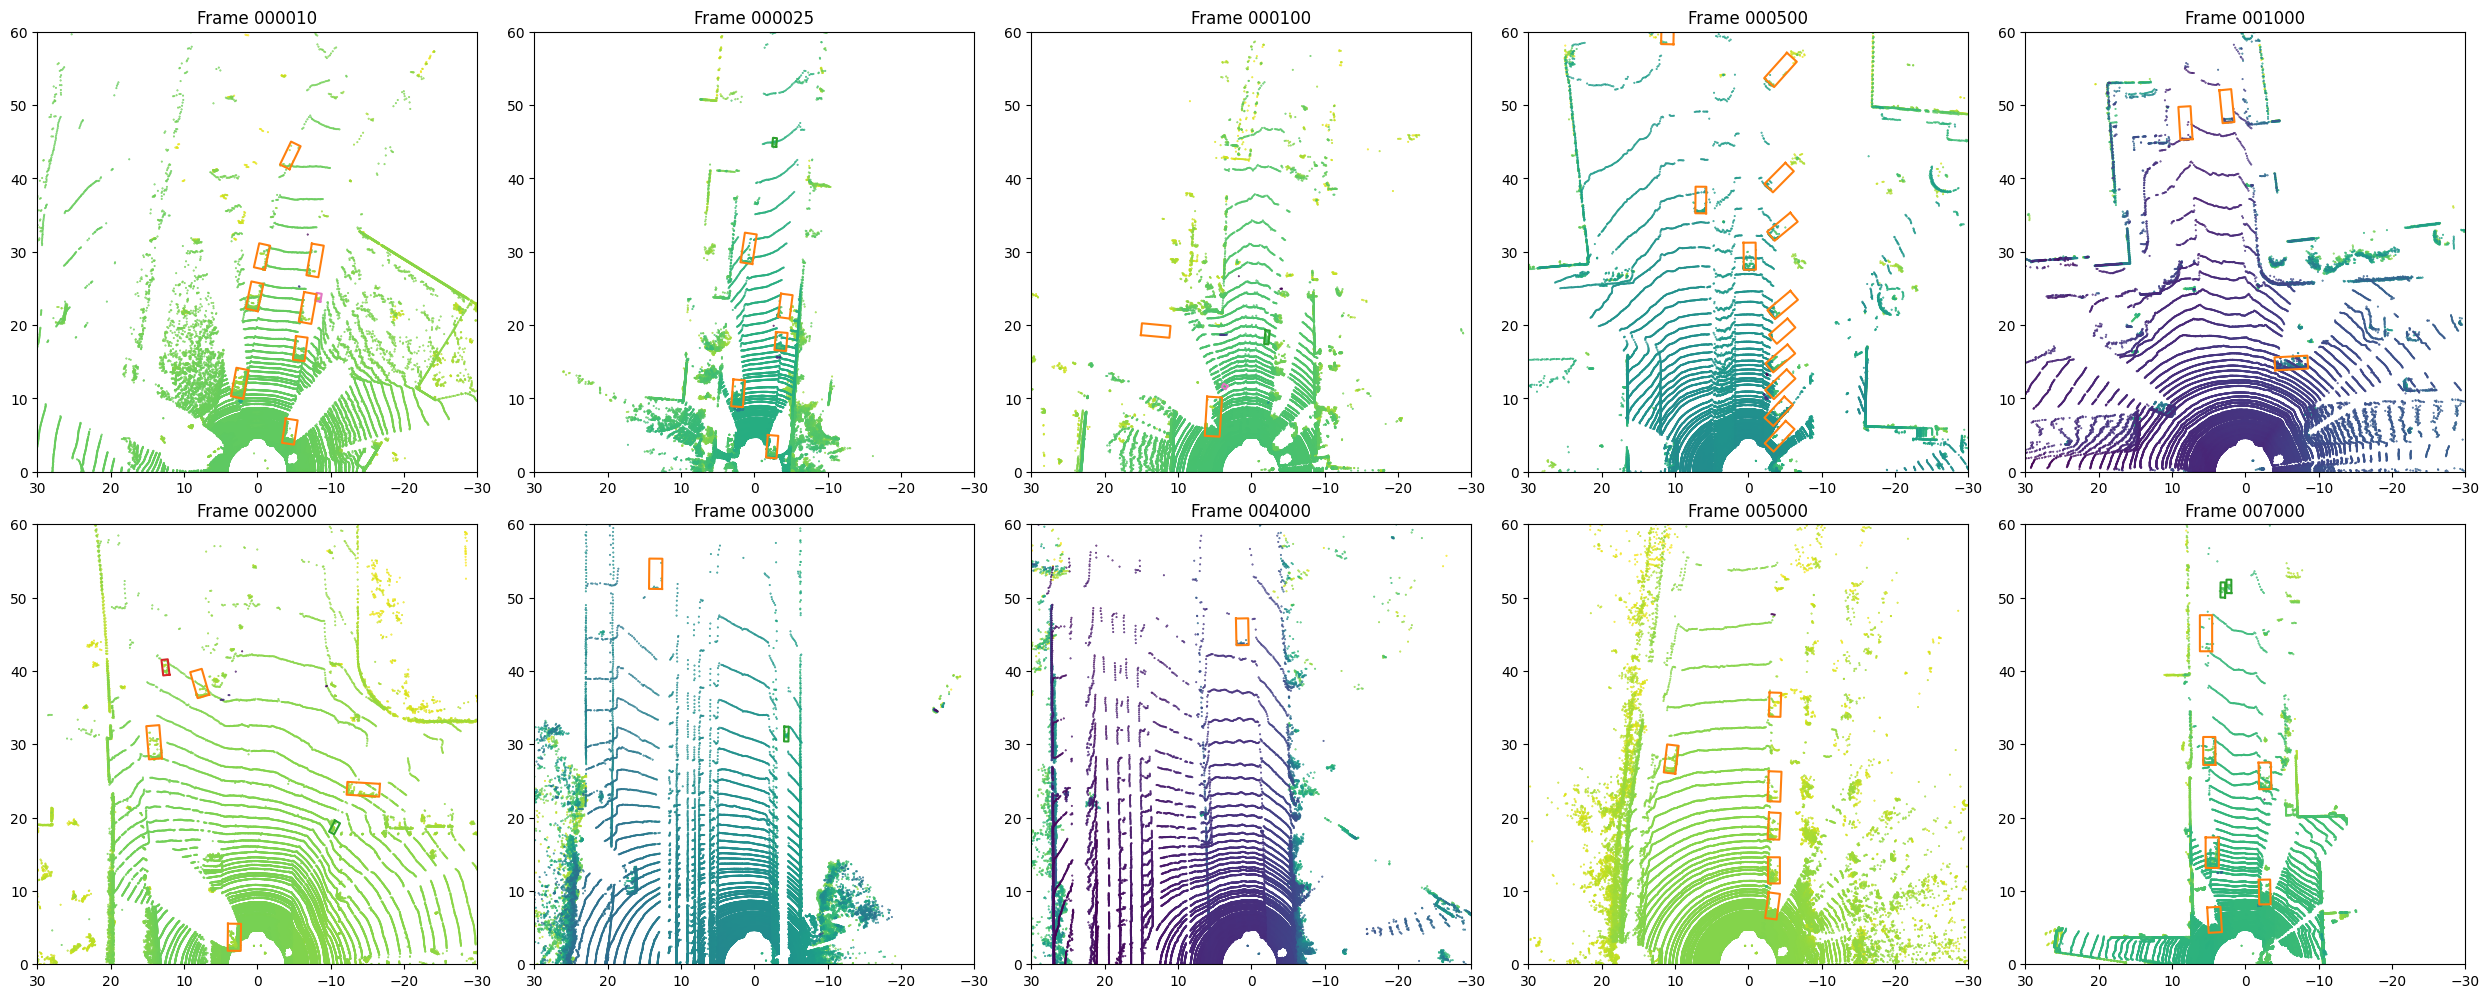

In [9]:
frames = ["000010", "000025", "000100", "000500", "001000",
          "002000", "003000", "004000", "005000", "007000"]
fig, axes = plt.subplots(2, 5, figsize=(25, 10))
for frame, ax in zip(frames, axes.flat):
    plot_bev(frame, ax)
plt.tight_layout()
plt.show()

In [10]:
def points_in_box(points: np.ndarray, box: dict) -> np.ndarray:
    """Boolean mask of points inside a 3D box."""
    shifted = points[:, :3] - box["centre"]
    c, s = np.cos(-box["yaw"]), np.sin(-box["yaw"])
    local_x = shifted[:, 0] * c - shifted[:, 1] * s
    local_y = shifted[:, 0] * s + shifted[:, 1] * c
    l, w, h = box["size"]
    return (np.abs(local_x) <= l/2) & (np.abs(local_y) <= w/2) & (np.abs(shifted[:, 2]) <= h/2)

points = load_scan("000010")
for obj in load_labels("000010", load_cam_to_velo("000010")):
    n = points_in_box(points, obj).sum()
    print(f"{obj['cls']:12s} {np.linalg.norm(obj['centre'][:2]):5.1f} m away  →  {n} points")

Car            7.0 m away  →  1628 points
Car           12.3 m away  →  1012 points
Pedestrian    25.2 m away  →  23 points
Car           17.8 m away  →  340 points
Car           23.4 m away  →  48 points
Car           23.9 m away  →  245 points
Car           29.4 m away  →  53 points
Car           29.9 m away  →  33 points
Car           43.4 m away  →  20 points


In [11]:
import pandas as pd

def label_flags(frame: str) -> list[tuple]:
    """(truncated, occluded) per object, same order as load_labels."""
    flags = []
    for line in (ROOT / "label_2" / f"{frame}.txt").read_text().splitlines():
        f = line.split()
        if f[0] != "DontCare":
            flags.append((float(f[1]), int(f[2])))
    return flags

def frame_stats(frame: str) -> list[dict]:
    points = load_scan(frame)
    points = points[points[:, 0] > -1]  # labels only exist in front of the car
    rows = []
    for obj, (trunc, occ) in zip(load_labels(frame, load_cam_to_velo(frame)), label_flags(frame)):
        inside = points[points_in_box(points, obj)]
        bottom = obj["centre"][2] - obj["size"][2] / 2
        rows.append({
            "frame": frame, "cls": obj["cls"],
            "dist": np.linalg.norm(obj["centre"][:2]),
            "angle": np.degrees(np.arctan2(obj["centre"][1], obj["centre"][0])),
            "n_points": len(inside),
            "l": obj["size"][0], "w": obj["size"][1], "h": obj["size"][2],
            "bottom_z": bottom,
            "gap": inside[:, 2].min() - bottom if len(inside) else np.nan,
            "truncated": trunc, "occluded": occ,
        })
    return rows

In [12]:
n_frames = len(list((ROOT / "label_2").iterdir()))
sample = [f"{i:06d}" for i in np.linspace(0, n_frames - 1, 500).astype(int)]

df = pd.DataFrame([row for frame in sample for row in frame_stats(frame)])
print(len(df), "objects from", len(sample), "frames")
df.head()

2737 objects from 500 frames


,frame,cls,dist,angle,n_points,l,w,h,bottom_z,gap,truncated,occluded
0,000000,Pedestrian,8.933850,-12.069559,377,1.20,0.48,1.89,-1.599790,0.000790,0.0,0
1,000014,Car,60.144932,-2.433576,16,4.39,1.68,1.44,-1.194231,0.154231,0.0,0
2,000029,Misc,23.725865,7.362067,206,2.07,1.21,1.61,-1.497187,0.016187,0.0,0
3,000029,Car,41.953282,-4.712167,61,3.30,1.69,1.64,-1.454687,0.012687,0.0,0
4,000044,Car,6.405420,30.792909,3149,3.67,1.62,1.44,-1.713076,0.000076,0.7,0


In [13]:
counts = df["cls"].value_counts()
print(counts)
print("\nper frame:", round(len(df) / len(sample), 1), "objects on average")

cls
Car               2007
Pedestrian         247
Van                177
Cyclist            113
Truck               68
Misc                66
Tram                43
Person_sitting      16
Name: count, dtype: int64

per frame: 5.5 objects on average


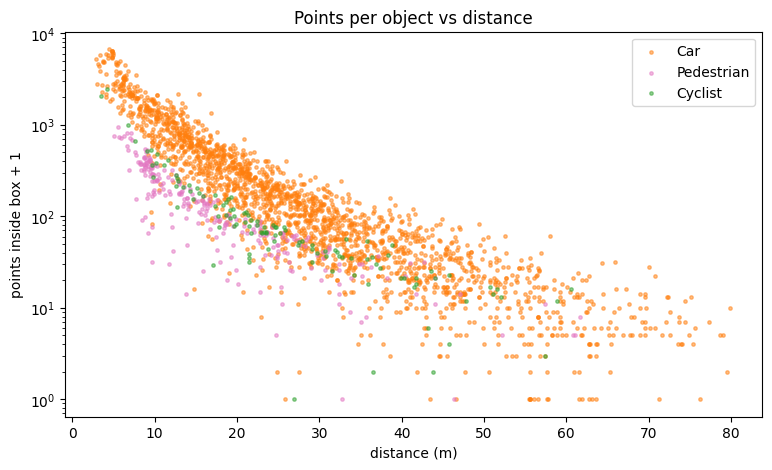

In [14]:
main = ["Car", "Pedestrian", "Cyclist"]
fig, ax = plt.subplots(figsize=(9, 5))
for cls in main:
    d = df[df["cls"] == cls]
    ax.scatter(d["dist"], d["n_points"] + 1, s=6, alpha=0.5, label=cls, color=COLOURS[cls])
ax.set(yscale="log", xlabel="distance (m)", ylabel="points inside box + 1",
       title="Points per object vs distance")
ax.legend()
plt.show()

In [15]:
bins = [0, 20, 40, 80]
df["range"] = pd.cut(df["dist"], bins, labels=["near <20", "mid 20-40", "far >40"])
df[df["cls"].isin(main)].groupby(["cls", "range"], observed=True)["n_points"].describe()[["count", "50%", "min", "max"]]

count    50%   min     max
cls        range                                
Car        near <20   665.0  669.0  15.0  6701.0
           mid 20-40  835.0   90.0   0.0   707.0
           far >40    507.0   15.0   0.0   119.0
Cyclist    near <20    40.0  184.0  28.0  2480.0
           mid 20-40   55.0   48.0   0.0   109.0
           far >40     18.0   15.0   1.0    24.0
Pedestrian near <20   158.0  181.5  13.0   937.0
           mid 20-40   76.0   40.5   0.0    92.0
           far >40     13.0   10.0   0.0    31.0

In [16]:
# objects that are almost empty - these break the feature step later
for k in [0, 5, 10]:
    print(f"<= {k:2d} points: {(df['n_points'] <= k).sum():4d}  ({(df['n_points'] <= k).mean():.1%})")

print("\nempty boxes by occlusion level (0 visible ... 3 unknown):")
print(df[df["n_points"] == 0]["occluded"].value_counts().sort_index())

<=  0 points:   27  (1.0%)
<=  5 points:  137  (5.0%)
<= 10 points:  229  (8.4%)

empty boxes by occlusion level (0 visible ... 3 unknown):
occluded
0     2
1     6
2    19
Name: count, dtype: int64


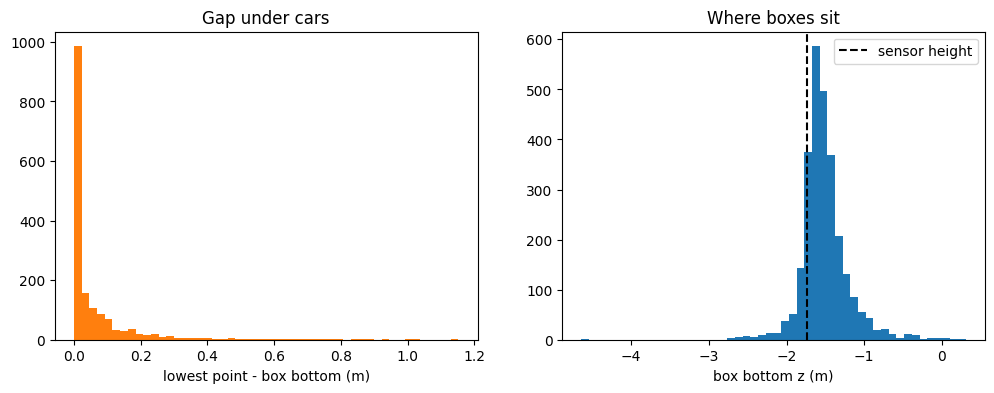

median gap: 0.011 m


In [17]:
# height check: lowest point inside a box should be close to the box bottom
cars = df[(df["cls"] == "Car") & (df["n_points"] >= 20)]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(cars["gap"], bins=50, color="tab:orange")
axes[0].set(xlabel="lowest point - box bottom (m)", title="Gap under cars")
axes[1].hist(df["bottom_z"], bins=50, color="tab:blue")
axes[1].axvline(-1.73, color="k", ls="--", label="sensor height")
axes[1].set(xlabel="box bottom z (m)", title="Where boxes sit")
axes[1].legend()
plt.show()
print("median gap:", round(cars["gap"].median(), 3), "m")

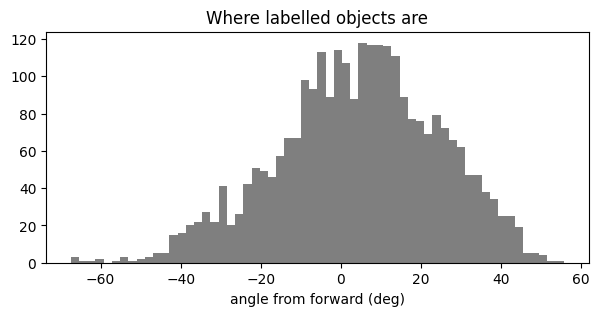

outside +-50 deg: 19


In [18]:
# labels should only be inside the front camera view (about +-45 deg)
plt.figure(figsize=(7, 3))
plt.hist(df["angle"], bins=60, color="tab:gray")
plt.xlabel("angle from forward (deg)")
plt.title("Where labelled objects are")
plt.show()
print("outside +-50 deg:", (df["angle"].abs() > 50).sum())

In [19]:
# box sizes per class - quick sanity check of l, w, h
df[df["cls"].isin(main)].groupby("cls")[["l", "w", "h"]].agg(["mean", "std"]).round(2)

l           w           h      
            mean   std  mean   std  mean   std
cls                                           
Car         3.89  0.43  1.63  0.10  1.52  0.14
Cyclist     1.76  0.17  0.59  0.13  1.74  0.09
Pedestrian  0.84  0.24  0.68  0.16  1.77  0.12

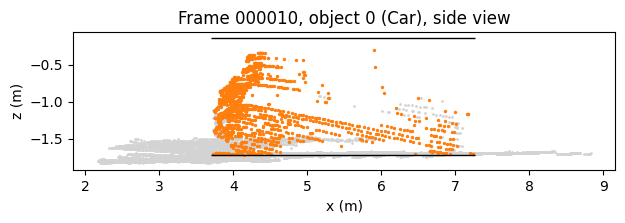

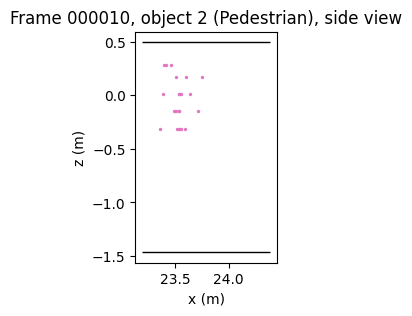

In [20]:
def plot_side(frame: str, index: int):
    """Side view (x-z) of one object with its box, to check the height."""
    points = load_scan(frame)
    obj = load_labels(frame, load_cam_to_velo(frame))[index]
    l, w, h = obj["size"]
    near = np.linalg.norm(points[:, :2] - obj["centre"][:2], axis=1) < max(l, w)
    inside = points_in_box(points, obj)
    plt.figure(figsize=(7, 3))
    plt.scatter(points[near & ~inside, 0], points[near & ~inside, 2], s=1, c="lightgray")
    plt.scatter(points[inside, 0], points[inside, 2], s=2, c=COLOURS.get(obj["cls"], "tab:red"))
    corners = np.vstack([bev_corners(obj), bev_corners(obj)[:1]])
    zb, zt = obj["centre"][2] - h / 2, obj["centre"][2] + h / 2
    plt.hlines([zb, zt], corners[:, 0].min(), corners[:, 0].max(), colors="k", lw=1)
    plt.gca().set_aspect("equal")
    plt.title(f"Frame {frame}, object {index} ({obj['cls']}), side view")
    plt.xlabel("x (m)"); plt.ylabel("z (m)")
    plt.show()

plot_side("000010", 0)
plot_side("000010", 2)

In [21]:
def cross(a, b):
    return a[0] * b[1] - a[1] * b[0]

def polygon_area(poly) -> float:
    if len(poly) < 3:
        return 0.0
    p = np.asarray(poly)
    return 0.5 * abs(np.dot(p[:, 0], np.roll(p[:, 1], -1)) - np.dot(p[:, 1], np.roll(p[:, 0], -1)))

def ccw(poly: np.ndarray) -> np.ndarray:
    """Return the polygon in counter-clockwise order."""
    signed = np.dot(poly[:, 0], np.roll(poly[:, 1], -1)) - np.dot(poly[:, 1], np.roll(poly[:, 0], -1))
    return poly if signed > 0 else poly[::-1]

def clip(subject, clipper) -> list:
    """Sutherland-Hodgman: part of convex polygon `subject` inside convex `clipper` (both CCW)."""
    out = list(subject)
    for i in range(len(clipper)):
        a, b = clipper[i], clipper[(i + 1) % len(clipper)]
        d = b - a
        inp, out = out, []
        for j in range(len(inp)):
            p, q = inp[j - 1], inp[j]
            cp, cq = cross(d, p - a), cross(d, q - a)
            if cq >= 0:
                if cp < 0:
                    out.append(p + cp / (cp - cq) * (q - p))
                out.append(q)
            elif cp >= 0:
                out.append(p + cp / (cp - cq) * (q - p))
        if not out:
            break
    return out

In [22]:
def iou_bev(a: dict, b: dict) -> float:
    """IoU of two boxes seen from above (rotated rectangles)."""
    inter = polygon_area(clip(ccw(bev_corners(a)), ccw(bev_corners(b))))
    area_a = a["size"][0] * a["size"][1]
    area_b = b["size"][0] * b["size"][1]
    return inter / (area_a + area_b - inter)

def iou_3d(a: dict, b: dict) -> float:
    """3D IoU = overlap area from above x overlap in height."""
    inter = polygon_area(clip(ccw(bev_corners(a)), ccw(bev_corners(b))))
    top = min(a["centre"][2] + a["size"][2] / 2, b["centre"][2] + b["size"][2] / 2)
    bottom = max(a["centre"][2] - a["size"][2] / 2, b["centre"][2] - b["size"][2] / 2)
    inter *= max(0.0, top - bottom)
    vol_a, vol_b = np.prod(a["size"]), np.prod(b["size"])
    return inter / (vol_a + vol_b - inter)

In [23]:
def box(x=0.0, y=0.0, z=0.0, l=4.0, w=2.0, h=1.5, yaw=0.0):
    return {"cls": "Car", "centre": np.array([x, y, z]), "size": (l, w, h), "yaw": yaw}

assert np.isclose(iou_3d(box(), box()), 1)                                 
assert np.isclose(iou_3d(box(), box(x=10)), 0)                              
assert np.isclose(iou_bev(box(), box(x=2)), 1 / 3)                          
assert np.isclose(iou_3d(box(), box(z=0.75)), 1 / 3)                        
assert np.isclose(iou_bev(box(), box(yaw=np.pi)), 1)                        
assert np.isclose(iou_bev(box(l=2, w=2), box(l=2, w=2, yaw=np.pi / 4)), np.sqrt(2) / 2) 
assert np.isclose(iou_bev(box(), box(x=4)), 0)                              
assert np.isclose(iou_bev(box(), box(yaw=np.pi / 2)), iou_bev(box(yaw=np.pi / 2), box()))  
print("IoU tests passed")

IoU tests passed


In [24]:

from shapely.geometry import Polygon

rng = np.random.default_rng(1)
worst = 0
for _ in range(2000):
    a = box(*rng.uniform(-2, 2, 2), 0, *rng.uniform(0.5, 5, 3), rng.uniform(-np.pi, np.pi))
    b = box(*rng.uniform(-2, 2, 2), 0, *rng.uniform(0.5, 5, 3), rng.uniform(-np.pi, np.pi))
    pa, pb = Polygon(bev_corners(a)), Polygon(bev_corners(b))
    ref = pa.intersection(pb).area / pa.union(pb).area
    worst = max(worst, abs(iou_bev(a, b) - ref))
print("max difference to shapely:", worst)
assert worst < 1e-9

max difference to shapely: 7.771561172376096e-16


In [25]:

all_frames = sorted(p.stem for p in (ROOT / "label_2").glob("*.txt"))
blocks = [all_frames[i:i + 50] for i in range(0, len(all_frames), 50)]
rng = np.random.default_rng(42)
val_blocks = set(rng.choice(len(blocks), size=max(1, round(0.2 * len(blocks))), replace=False))

train = [f for i, b in enumerate(blocks) if i not in val_blocks for f in b]
val = [f for i, b in enumerate(blocks) if i in val_blocks for f in b]
assert not set(train) & set(val)
OUT = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")
(OUT / "train.txt").write_text("\n".join(train))
(OUT / "val.txt").write_text("\n".join(val))
print(len(train), "train frames,", len(val), "val frames")

5981 train frames, 1500 val frames


In [26]:
TARGET = {"Car": "Car", "Van": "Car", "Pedestrian": "Pedestrian", "Person_sitting": "Pedestrian",
          "Cyclist": "Cyclist"}   # everything else -> Other

def shape_features(pts: np.ndarray) -> dict:
    """Features from the points only, so they also work later on our own clusters."""
    xyz = pts[:, :3]
    z = xyz[:, 2]
    f = {"z_min": z.min(), "z_max": z.max(), "height": np.ptp(z), "z_std": z.std(),
         "intensity_mean": pts[:, 3].mean(), "intensity_std": pts[:, 3].std()}
    if len(pts) >= 3:
        xy = xyz[:, :2] - xyz[:, :2].mean(axis=0)
        _, vecs = np.linalg.eigh(np.cov(xy.T))
        proj = xy @ vecs
        f["extent_long"], f["extent_short"] = np.ptp(proj[:, 1]), np.ptp(proj[:, 0])
        e = np.sort(np.linalg.eigvalsh(np.cov(xyz.T)))[::-1] + 1e-9
        f["linearity"], f["planarity"], f["scattering"] = (e[0] - e[1]) / e[0], (e[1] - e[2]) / e[0], e[2] / e[0]
        f["density"] = len(pts) / (f["extent_long"] * f["extent_short"] * f["height"] + 1e-3)
    return f

def frame_features(frame: str) -> list[dict]:
    points = load_scan(frame)
    points = points[points[:, 0] > -1]
    rows = []
    for obj, (trunc, occ) in zip(load_labels(frame, load_cam_to_velo(frame)), label_flags(frame)):
        inside = points[points_in_box(points, obj)]
        row = {"frame": frame, "cls": obj["cls"], "target": TARGET.get(obj["cls"], "Other"),
               "n_points": len(inside), "dist": np.linalg.norm(obj["centre"][:2]),
               "angle": np.degrees(np.arctan2(obj["centre"][1], obj["centre"][0])),
               "l": obj["size"][0], "w": obj["size"][1], "h": obj["size"][2],
               "truncated": trunc, "occluded": occ}
        if len(inside):
            row.update(shape_features(inside))
        rows.append(row)
    return rows

In [27]:
import time

split_of = {**{f: "train" for f in train}, **{f: "val" for f in val}}
rows = []
start = time.perf_counter()
for i, frame in enumerate(all_frames):
    rows += frame_features(frame)
    if i % 1000 == 0:
        print(f"{i:5d}/{len(all_frames)}  {time.perf_counter() - start:.0f} s")

feats = pd.DataFrame(rows)
feats["split"] = feats["frame"].map(split_of)
print(len(feats), "objects")

    0/7481  0 s
 1000/7481  249 s
 2000/7481  488 s
 3000/7481  737 s
 4000/7481  981 s
 5000/7481  1229 s
 6000/7481  1478 s
 7000/7481  1733 s
40570 objects


In [28]:

pd.crosstab(feats["cls"], feats["split"], margins=True)

split,train,val,All
cls,,,
Car,23112,5630,28742
Cyclist,1295,332,1627
Misc,771,202,973
Pedestrian,3552,935,4487
Person_sitting,192,30,222
Tram,414,97,511
Truck,856,238,1094
Van,2334,580,2914
All,32526,8044,40570


In [29]:
pd.crosstab(feats["target"], feats["split"], normalize="columns").round(3)

split,train,val
target,,
Car,0.782,0.772
Cyclist,0.040,0.041
Other,0.063,0.067
Pedestrian,0.115,0.120


In [30]:

MIN_POINTS = 5
usable = feats[feats["n_points"] >= MIN_POINTS]
print(f"kept {len(usable)} of {len(feats)} objects ({len(usable) / len(feats):.1%})")
print(usable.isna().sum()[usable.isna().sum() > 0])

feats.to_csv(OUT / "features_all.csv", index=False)
usable.to_csv(OUT / "features.csv", index=False)
print("saved to", OUT)

kept 39074 of 40570 objects (96.3%)
Series([], dtype: int64)
saved to /kaggle/working


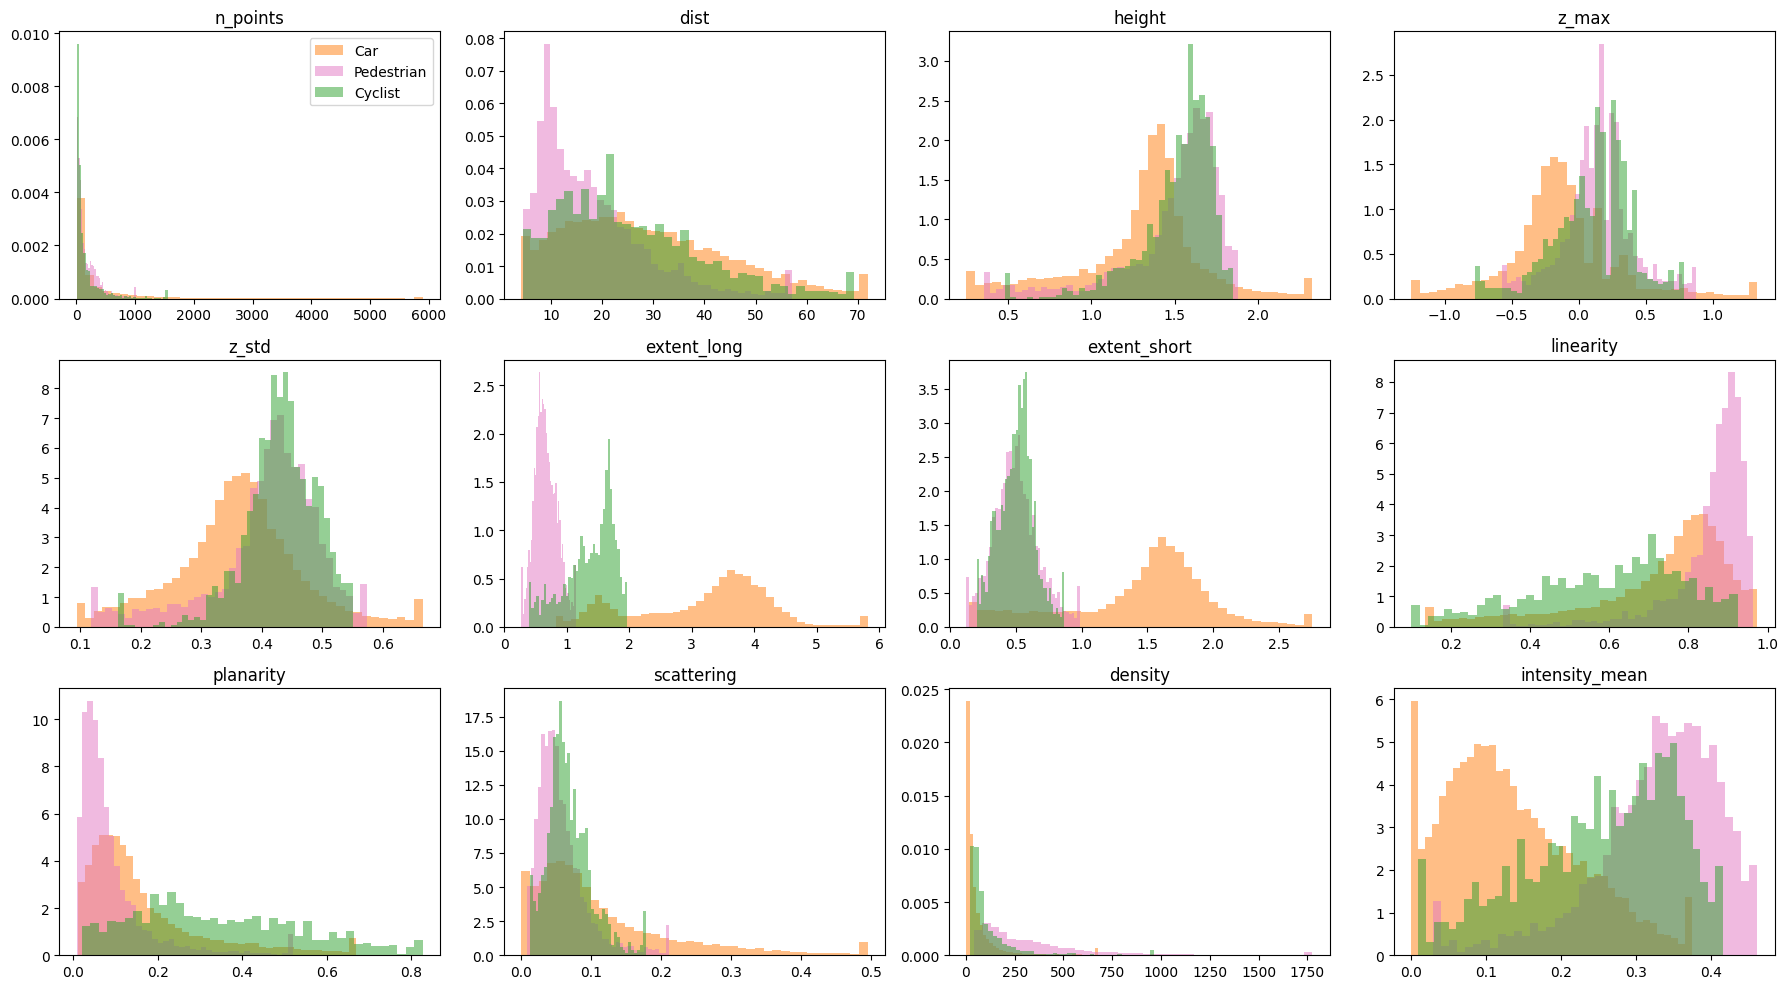

In [31]:
feature_cols = ["n_points", "dist", "height", "z_max", "z_std", "extent_long", "extent_short",
                "linearity", "planarity", "scattering", "density", "intensity_mean"]
main = ["Car", "Pedestrian", "Cyclist"]
fig, axes = plt.subplots(3, 4, figsize=(18, 10))
for col, ax in zip(feature_cols, axes.flat):
    for cls in main:
        d = usable.loc[(usable["target"] == cls) & (usable["split"] == "train"), col]
        ax.hist(d.clip(*d.quantile([0.01, 0.99])), bins=40, alpha=0.5, density=True,
                label=cls, color=COLOURS[cls])
    ax.set_title(col)
axes.flat[0].legend()
plt.tight_layout()
plt.show()

In [32]:

check = pd.read_csv(OUT / "features.csv", dtype={"frame": str})
assert len(check) == len(usable) and set(check["split"]) == {"train", "val"}
check.groupby(["split", "target"]).size().unstack()

target,Car,Cyclist,Other,Pedestrian
split,,,,
train,24413,1267,1976,3703
val,5921,325,521,948


## Session 3: comparing our boxes with the KITTI boxes
Matching uses our IoU. A predicted box that overlaps a KITTI car with IoU >= 0.5 is a hit (TP),
a KITTI car with no match is missed (FN), a predicted box with no match is a false alarm (FP).
Only cars are scored. A prediction sitting on a Van/Truck is ignored, not counted as wrong.

In [33]:
import copy
import time

TARGET = "Car"
IGNORE = {"Van", "Truck", "Tram", "Misc"}
RANGES = [(0, 20, "near <20"), (20, 40, "mid 20-40"), (40, 80, "far >40")]

def range_name(d):
    for lo, hi, name in RANGES:
        if lo <= d < hi:
            return name
    return "beyond"

def match_boxes(preds, gts, iou_fn=iou_bev, thr=0.5):
    """Greedy matching, highest IoU first."""
    if not preds or not gts:
        return [], list(range(len(preds))), list(range(len(gts)))
    iou = np.array([[iou_fn(p, g) for g in gts] for p in preds])
    pairs, used_p, used_g = [], set(), set()
    for flat in np.argsort(-iou, axis=None):
        i, j = np.unravel_index(flat, iou.shape)
        if iou[i, j] < thr:
            break
        if i in used_p or j in used_g:
            continue
        pairs.append((i, j, iou[i, j]))
        used_p.add(i)
        used_g.add(j)
    fp = [i for i in range(len(preds)) if i not in used_p]
    fn = [j for j in range(len(gts)) if j not in used_g]
    return pairs, fp, fn

def score_frame(preds, gts_all, iou_fn=iou_bev, thr=0.5, min_points=0, points=None):
    preds = [p for p in preds if p["cls"] == TARGET]
    gts, ignore = [], []
    for g in gts_all:
        too_few = min_points and points is not None and points_in_box(points, g).sum() < min_points
        if g["cls"] == TARGET and not too_few:
            gts.append(g)
        elif g["cls"] == TARGET or g["cls"] in IGNORE:
            ignore.append(g)   # cars with almost no points, vans, trucks...

    pairs, fp, fn = match_boxes(preds, gts, iou_fn, thr)
    _, fp_left, _ = match_boxes([preds[i] for i in fp], ignore, iou_fn, thr)
    fp = [fp[k] for k in fp_left]

    dist = lambda b: np.linalg.norm(b["centre"][:2])
    rows = [{"type": "tp", "range": range_name(dist(gts[j])), "iou": v} for i, j, v in pairs]
    rows += [{"type": "fn", "range": range_name(dist(gts[j])), "iou": np.nan} for j in fn]
    rows += [{"type": "fp", "range": range_name(dist(preds[i])), "iou": np.nan} for i in fp]
    return rows

def summarise(rows):
    ev = pd.DataFrame(rows, columns=["type", "range", "iou"])
    out = []
    for name in [r[2] for r in RANGES] + ["all"]:
        e = ev if name == "all" else ev[ev["range"] == name]
        tp, fp, fn = (e["type"] == "tp").sum(), (e["type"] == "fp").sum(), (e["type"] == "fn").sum()
        out.append({"range": name, "TP": tp, "FP": fp, "FN": fn,
                    "precision": tp / (tp + fp) if tp + fp else np.nan,
                    "recall": tp / (tp + fn) if tp + fn else np.nan,
                    "mean IoU": e.loc[e["type"] == "tp", "iou"].mean()})
    return pd.DataFrame(out).set_index("range").round(3)

def evaluate(frames, predict_fn, iou_fn=iou_bev, thr=0.5, min_points=10):
    rows = []
    for frame in frames:
        points = load_scan(frame)
        gts = load_labels(frame, load_cam_to_velo(frame))
        rows += score_frame(predict_fn(frame), gts, iou_fn, thr, min_points, points)
    return summarise(rows)

In [34]:
# check the scoring itself before trusting any number from it
test_frames = val[:200]
gt_of = {f: load_labels(f, load_cam_to_velo(f)) for f in test_frames}

def shifted(boxes, dy):
    out = copy.deepcopy(boxes)
    for b in out:
        b["centre"] = b["centre"] + np.array([0, dy, 0])
    return out

rng = np.random.default_rng(0)
def with_fakes(f):
    return gt_of[f] + [box(x=rng.uniform(5, 60), y=rng.uniform(-20, 20), z=-0.9, l=4, w=1.7, h=1.5,
                           yaw=rng.uniform(-np.pi, np.pi)) for _ in range(3)]

same = evaluate(test_frames, lambda f: gt_of[f], min_points=0)
moved = evaluate(test_frames, lambda f: shifted(gt_of[f], 1.0), min_points=0)
half = evaluate(test_frames, lambda f: gt_of[f][::2], min_points=0)
fakes = evaluate(test_frames, with_fakes, min_points=0)

assert same.loc["all", "precision"] == 1 and same.loc["all", "recall"] == 1
assert half.loc["all", "precision"] == 1 and fakes.loc["all", "recall"] == 1
print(pd.DataFrame({"labels vs labels": same["recall"], "shifted 1 m": moved["recall"],
                    "half removed": half["recall"]}).rename_axis("recall"))
print("\nprecision with 3 fake cars per frame:", fakes.loc["all", "precision"])

           labels vs labels  shifted 1 m  half removed
recall                                                
near <20                1.0        0.140         0.597
mid 20-40               1.0        0.099         0.568
far >40                 1.0        0.074         0.530
all                     1.0        0.104         0.565

precision with 3 fake cars per frame: 0.543


### Box fitting
L-shape fit: try headings from 0 to 90 degrees, keep the one where the points are closest to the
rectangle edges. Tested on the points inside the real KITTI car boxes, so we know the right answer.
LiDAR only sees one or two sides of a car, so the box comes out too small. `complete_car` grows it to
the average car size (3.9 x 1.6 m from our stats) on the side away from the sensor.

In [35]:
def fit_box(pts, cls="Car", ground_z=None, n_angles=90):
    xy = pts[:, :2]
    best, best_t = -np.inf, 0.0
    for t in np.linspace(0, np.pi / 2, n_angles, endpoint=False):
        c1 = xy @ np.array([np.cos(t), np.sin(t)])
        c2 = xy @ np.array([-np.sin(t), np.cos(t)])
        d1 = np.minimum(c1.max() - c1, c1 - c1.min())
        d2 = np.minimum(c2.max() - c2, c2 - c2.min())
        score = (1 / np.maximum(np.minimum(d1, d2), 0.05)).sum()
        if score > best:
            best, best_t = score, t

    e1 = np.array([np.cos(best_t), np.sin(best_t)])
    e2 = np.array([-np.sin(best_t), np.cos(best_t)])
    c1, c2 = xy @ e1, xy @ e2
    a, b = np.ptp(c1), np.ptp(c2)
    mid = e1 * (c1.max() + c1.min()) / 2 + e2 * (c2.max() + c2.min()) / 2
    yaw = best_t if a >= b else best_t + np.pi / 2
    z_lo = pts[:, 2].min() if ground_z is None else ground_z
    z_hi = pts[:, 2].max()
    return {"cls": cls, "centre": np.array([mid[0], mid[1], (z_lo + z_hi) / 2]),
            "size": (max(a, b), min(a, b), z_hi - z_lo), "yaw": yaw}

CAR_L, CAR_W = 3.9, 1.6

def complete_car(b):
    l, w, h = b["size"]
    L, W = max(l, CAR_L), max(w, CAR_W)
    along = np.array([np.cos(b["yaw"]), np.sin(b["yaw"])])
    across = np.array([-np.sin(b["yaw"]), np.cos(b["yaw"])])
    centre = b["centre"].copy()
    away = centre[:2] / np.linalg.norm(centre[:2])
    centre[:2] += along * np.sign(away @ along) * (L - l) / 2 + across * np.sign(away @ across) * (W - w) / 2
    return {**b, "centre": centre, "size": (L, W, h)}

def yaw_error(a, b):
    # boxes are symmetric, so 0 and 180 degrees are the same heading
    return np.degrees(np.abs((a - b + np.pi / 2) % np.pi - np.pi / 2))

rows = []
for frame in val[:300]:
    points = load_scan(frame)
    for g in load_labels(frame, load_cam_to_velo(frame)):
        if g["cls"] != "Car":
            continue
        inside = points[points_in_box(points, g)]
        if len(inside) < 10:
            continue
        raw = fit_box(inside)
        full = complete_car(raw)
        rows.append({"dist": np.linalg.norm(g["centre"][:2]), "n_points": len(inside),
                     "iou raw": iou_bev(raw, g), "iou completed": iou_bev(full, g),
                     "iou 3d": iou_3d(full, g), "yaw error": yaw_error(full["yaw"], g["yaw"])})
fitq = pd.DataFrame(rows)
fitq["range"] = fitq["dist"].apply(range_name)
print(len(fitq), "cars")
fitq.groupby("range")[["iou raw", "iou completed", "iou 3d", "yaw error"]].median().round(3)

920 cars


,iou raw,iou completed,iou 3d,yaw error
range,,,,
far >40,0.446,0.710,0.358,6.281
mid 20-40,0.765,0.846,0.744,0.954
near <20,0.936,0.915,0.873,0.316


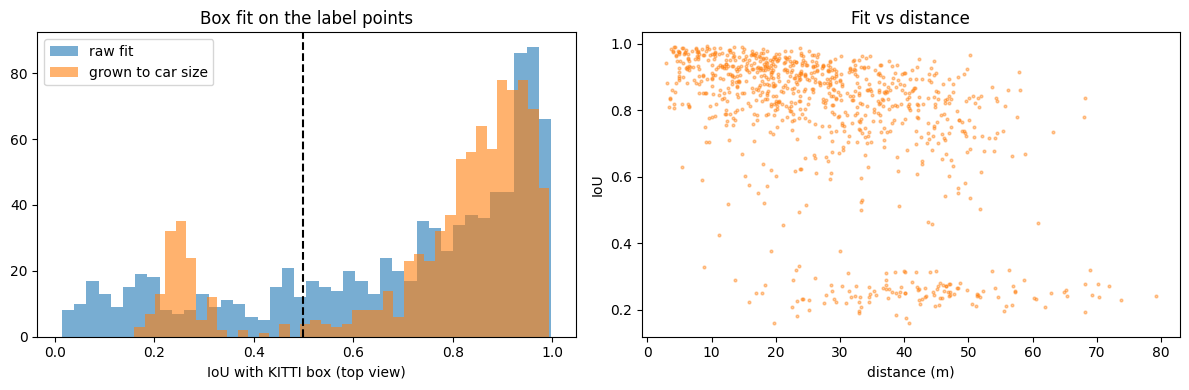

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(fitq["iou raw"], bins=40, alpha=0.6, label="raw fit")
axes[0].hist(fitq["iou completed"], bins=40, alpha=0.6, label="grown to car size")
axes[0].axvline(0.5, color="k", ls="--")
axes[0].legend()
axes[0].set(xlabel="IoU with KITTI box (top view)", title="Box fit on the label points")
axes[1].scatter(fitq["dist"], fitq["iou completed"], s=4, alpha=0.4, color="tab:orange")
axes[1].set(xlabel="distance (m)", ylabel="IoU", title="Fit vs distance")
plt.tight_layout()
plt.show()

### Car size rule
Checked on the features we saved last session. They are measured from the points only (not the label),
so they look like what a cluster will give us.

In [37]:
def car_rule(extent_long, extent_short, height):
    return ((extent_long >= 1.5) & (extent_long <= 6.5) & (extent_short >= 0.5) & (extent_short <= 2.8)
            & (height >= 0.7) & (height <= 2.3) & (extent_long * extent_short >= 1.0))

tr = usable[usable["split"] == "train"].copy()
tr["rule_says_car"] = car_rule(tr["extent_long"], tr["extent_short"], tr["height"])
print(pd.crosstab(tr["target"], tr["rule_says_car"], normalize="index").round(3))
print("\nby distance (real cars only):")
cars_tr = tr[tr["target"] == "Car"]
print(cars_tr.groupby(pd.cut(cars_tr["dist"], [0, 20, 40, 80]), observed=True)["rule_says_car"].mean().round(3))

rule_says_car  False  True 
target                     
Car            0.201  0.799
Cyclist        0.808  0.192
Other          0.749  0.251
Pedestrian     1.000  0.000

by distance (real cars only):
dist
(0, 20]     0.961
(20, 40]    0.862
(40, 80]    0.465
Name: rule_says_car, dtype: float64


### Ali's ground removal and clustering
Copied from Ali's notebook (task-2-ali) so the whole pipeline runs here.

In [38]:
from collections import deque

def voxel_downsample(points, size=0.1):
    keys = np.floor(points[:, :3] / size).astype(np.int64)
    _, inv, counts = np.unique(keys, axis=0, return_inverse=True, return_counts=True)
    sums = np.zeros((len(counts), points.shape[1]))
    np.add.at(sums, inv.ravel(), points)
    return (sums / counts[:, None]).astype(np.float32)

def plane_height(points, plane):
    return points[:, :3] @ plane[:3] + plane[3]

def fit_plane_lsq(points):
    centre = points[:, :3].mean(axis=0)
    normal = np.linalg.svd(points[:, :3] - centre, full_matrices=False)[2][-1]
    if normal[2] < 0:
        normal = -normal
    return np.append(normal, -normal @ centre)

def ransac_ground(points, thr=0.15, n_iter=150, max_tilt=25, seed=0):
    rng = np.random.default_rng(seed)
    cand = points[points[:, 2] < -1.0]
    if len(cand) < 50:
        cand = points
    idx = rng.integers(0, len(cand), (n_iter, 3))
    p0, p1, p2 = cand[idx[:, 0], :3], cand[idx[:, 1], :3], cand[idx[:, 2], :3]
    n = np.cross(p1 - p0, p2 - p0)
    length = np.linalg.norm(n, axis=1)
    ok = length > 1e-6
    n[ok] /= length[ok, None]
    n[n[:, 2] < 0] *= -1
    ok &= n[:, 2] > np.cos(np.deg2rad(max_tilt))
    n, p0 = n[ok], p0[ok]
    d = -(n * p0).sum(axis=1)
    sub = cand[rng.choice(len(cand), min(len(cand), 4000), replace=False), :3]
    cost = np.minimum((sub @ n.T + d) ** 2, thr ** 2).sum(axis=0)
    plane = np.append(n[np.argmin(cost)], d[np.argmin(cost)])
    for _ in range(2):
        plane = fit_plane_lsq(points[np.abs(plane_height(points, plane)) < thr])
    return plane, np.abs(plane_height(points, plane)) < thr

def grid_cluster(points, cell=0.3, min_points=10):
    ij = np.floor(points[:, :2] / cell).astype(np.int64)
    cells, inv = np.unique(ij, axis=0, return_inverse=True)
    inv = inv.ravel()
    lookup = {tuple(c): k for k, c in enumerate(cells)}
    cell_label = np.full(len(cells), -1)
    n_clusters = 0
    for start in range(len(cells)):
        if cell_label[start] != -1:
            continue
        cell_label[start] = n_clusters
        queue = deque([start])
        while queue:
            i, j = cells[queue.popleft()]
            for di in (-1, 0, 1):
                for dj in (-1, 0, 1):
                    nb = lookup.get((i + di, j + dj))
                    if nb is not None and cell_label[nb] == -1:
                        cell_label[nb] = n_clusters
                        queue.append(nb)
        n_clusters += 1
    labels = cell_label[inv]
    sizes = np.bincount(labels)
    labels[sizes[labels] < min_points] = -1
    return labels

### Checking the ground removal with the KITTI boxes
KITTI has no road labels, but the boxes help:
- points inside a box and more than 30 cm above its bottom are the object, they must be kept
- the bottom of each box should sit on our plane, if not the plane is wrong there (slope)

In [39]:
def crop_front(points):
    # KITTI only labels what the front camera sees
    ang = np.degrees(np.arctan2(points[:, 1], points[:, 0]))
    return points[(points[:, 0] > 0) & (points[:, 0] < 70) & (np.abs(ang) < 45) & (points[:, 2] < 1.0)]

def ground_report(frames, ground_fn=ransac_ground, keep_above=0.2):
    rows = []
    for frame in frames:
        p = voxel_downsample(crop_front(load_scan(frame)), 0.1)
        plane, _ = ground_fn(p)
        kept = plane_height(p, plane) > keep_above
        body_total = body_kept = 0
        bottom_err = []
        for g in load_labels(frame, load_cam_to_velo(frame)):
            if g["cls"] not in ("Car", "Van", "Pedestrian", "Cyclist"):
                continue
            bottom_z = g["centre"][2] - g["size"][2] / 2
            body = points_in_box(p, g) & (p[:, 2] > bottom_z + 0.3)
            body_total += body.sum()
            body_kept += (body & kept).sum()
            bottom = np.array([[g["centre"][0], g["centre"][1], bottom_z]])
            bottom_err.append(abs(plane_height(bottom, plane)[0]))
        rows.append({"frame": frame, "removed %": 100 * (1 - kept.mean()),
                     "object points kept %": 100 * body_kept / body_total if body_total else np.nan,
                     "box bottom to plane (m)": np.median(bottom_err) if bottom_err else np.nan})
    return pd.DataFrame(rows)

gr = ground_report(val[:100])
print(gr.drop(columns="frame").describe().round(2))
print("\nplane more than 30 cm off under the cars:")
print(gr[gr["box bottom to plane (m)"] > 0.3].round(2).to_string(index=False))

       removed %  object points kept %  box bottom to plane (m)
count     100.00                 99.00                   100.00
mean       56.49                 98.27                     0.08
std        12.67                  5.81                     0.08
min        28.60                 60.00                     0.00
25%        46.16                100.00                     0.03
50%        56.49                100.00                     0.05
75%        66.52                100.00                     0.10
max        90.14                100.00                     0.51

plane more than 30 cm off under the cars:
 frame  removed %  object points kept %  box bottom to plane (m)
000601      67.16                 82.35                     0.40
000622      71.81                 78.79                     0.51
000635      64.02                 75.00                     0.32


## Session 4: full pipeline and final results
crop -> voxel 0.1 m -> RANSAC ground -> grid clusters -> L-shape box -> car rule -> grow to car size

In [40]:
def predict(frame, cell=0.3, debug=False):
    p = voxel_downsample(crop_front(load_scan(frame)), 0.1)
    plane, _ = ransac_ground(p)
    above = p[plane_height(p, plane) > 0.2]
    labels = grid_cluster(above, cell)
    a, b, c, d = plane
    boxes = []
    for k in set(labels) - {-1}:
        cl = above[labels == k]
        cx, cy = cl[:, 0].mean(), cl[:, 1].mean()
        bx = fit_box(cl, ground_z=-(a * cx + b * cy + d) / c)
        l, w, h = bx["size"]
        if car_rule(l, w, h):
            boxes.append(complete_car(bx))
    if debug:
        return boxes, p, above, labels
    return boxes

# choose the grid cell size on train frames only
tune_frames = train[::60][:100]
rows = []
for cell in [0.2, 0.3, 0.4, 0.5]:
    r = evaluate(tune_frames, lambda f: predict(f, cell))
    rows.append({"cell": cell, "precision": r.loc["all", "precision"], "recall": r.loc["all", "recall"]})
tune = pd.DataFrame(rows)
tune["F1"] = 2 * tune["precision"] * tune["recall"] / (tune["precision"] + tune["recall"])
CELL = float(tune.loc[tune["F1"].idxmax(), "cell"])
print(tune.round(3).to_string(index=False))
print("using cell =", CELL)

 cell  precision  recall    F1
  0.2      0.239   0.461 0.315
  0.3      0.240   0.510 0.326
  0.4      0.256   0.528 0.345
  0.5      0.262   0.482 0.339
using cell = 0.4


In [41]:
start = time.perf_counter()
final_bev = evaluate(val[:300], lambda f: predict(f, CELL), iou_fn=iou_bev)
print(f"{1000 * (time.perf_counter() - start) / 300:.0f} ms per frame")
print("\nCars, top-view IoU >= 0.5 (300 val frames)")
final_bev

268 ms per frame

Cars, top-view IoU >= 0.5 (300 val frames)


,TP,FP,FN,precision,recall,mean IoU
range,,,,,,
near <20,222,249,97,0.471,0.696,0.796
mid 20-40,183,557,207,0.247,0.469,0.797
far >40,39,895,172,0.042,0.185,0.786
all,444,1701,476,0.207,0.483,0.795


In [42]:
final_3d = evaluate(val[:300], lambda f: predict(f, CELL), iou_fn=iou_3d)
print("Cars, 3D IoU >= 0.5")
final_3d

Cars, 3D IoU >= 0.5


,TP,FP,FN,precision,recall,mean IoU
range,,,,,,
near <20,212,261,107,0.448,0.665,0.756
mid 20-40,175,566,215,0.236,0.449,0.718
far >40,34,902,177,0.036,0.161,0.679
all,421,1729,499,0.196,0.458,0.734


### Figures for the report

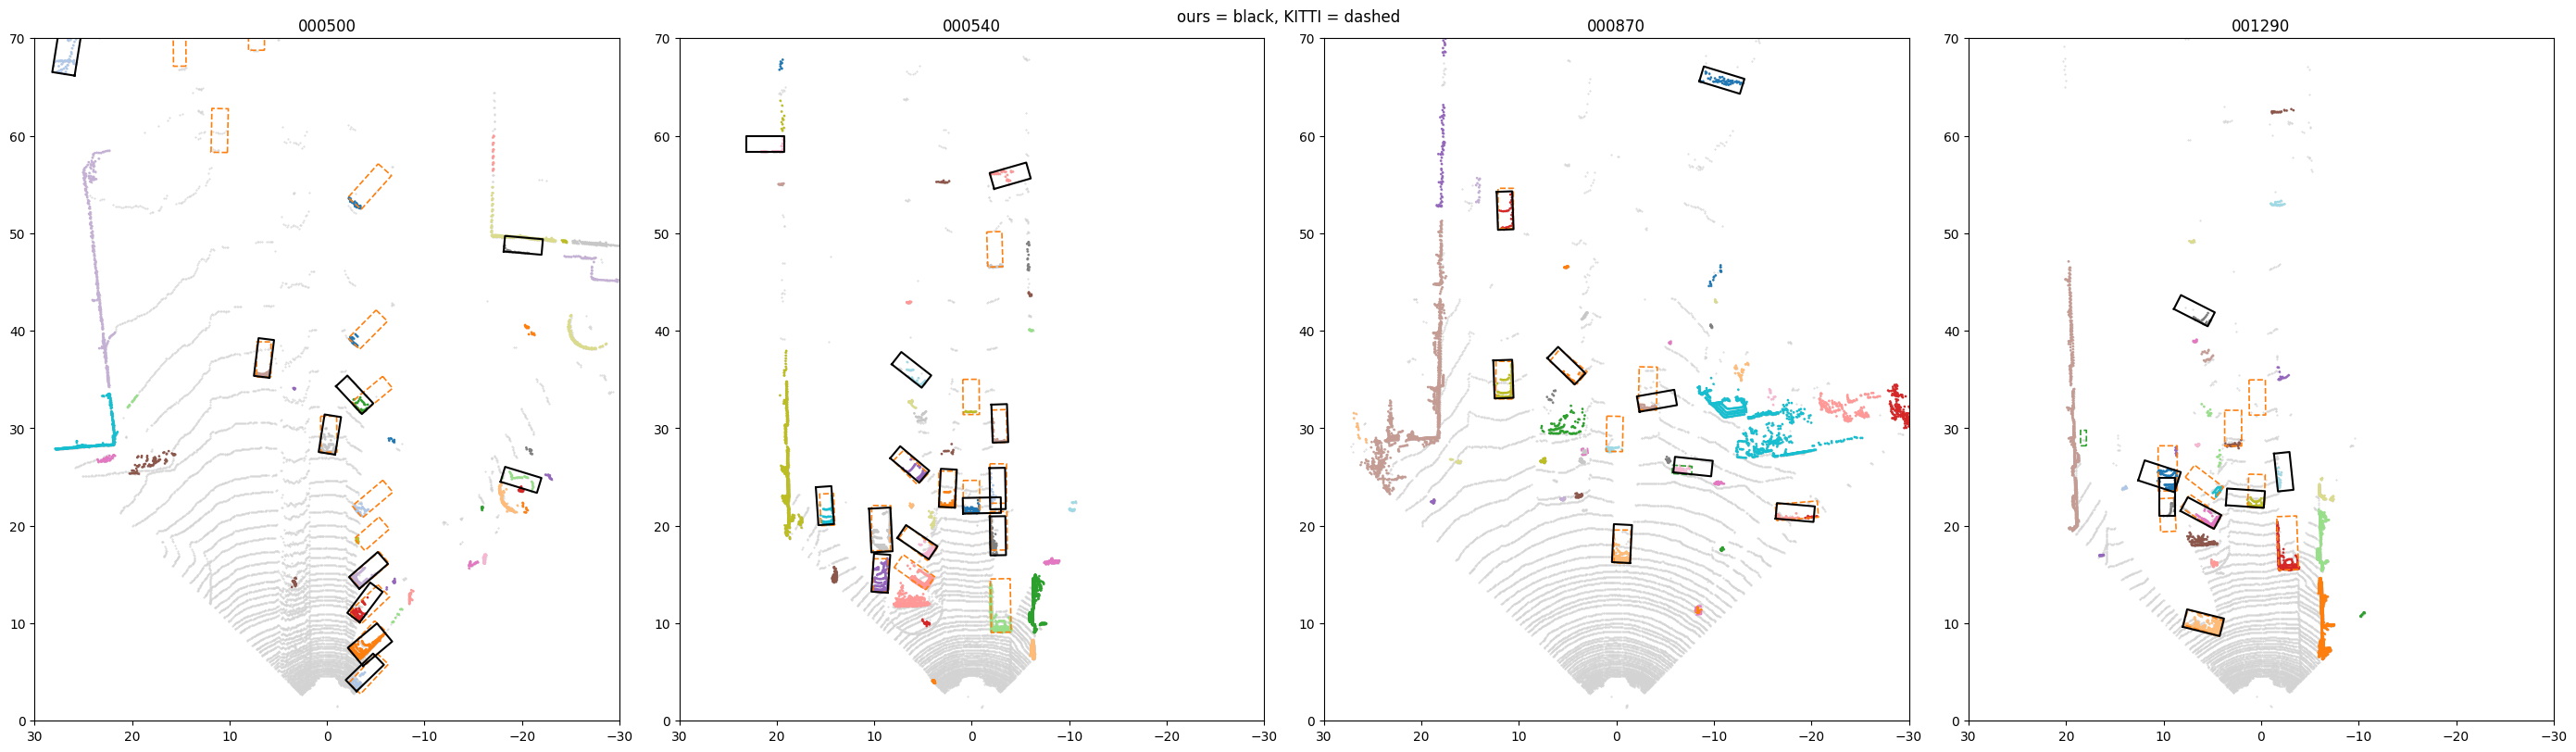

In [43]:
def plot_result(frame, ax=None):
    boxes, p, above, labels = predict(frame, CELL, debug=True)
    ax = ax or plt.subplots(figsize=(8, 8))[1]
    ax.scatter(p[:, 1], p[:, 0], s=0.2, c="lightgray")
    keep = labels >= 0
    ax.scatter(above[keep, 1], above[keep, 0], s=0.8, c=labels[keep] % 20, cmap="tab20")
    for g in load_labels(frame, load_cam_to_velo(frame)):
        poly = np.vstack([bev_corners(g), bev_corners(g)[:1]])
        ax.plot(poly[:, 1], poly[:, 0], "--", lw=1.2, color=COLOURS.get(g["cls"], "tab:red"))
    for b in boxes:
        poly = np.vstack([bev_corners(b), bev_corners(b)[:1]])
        ax.plot(poly[:, 1], poly[:, 0], color="black", lw=1.5)
    ax.set(xlim=(30, -30), ylim=(0, 70), aspect="equal", title=frame)
    return ax

fig, axes = plt.subplots(1, 4, figsize=(28, 8))
for f, ax in zip([val[0], val[40], val[120], val[190]], axes):
    plot_result(f, ax)
plt.suptitle("ours = black, KITTI = dashed")
plt.tight_layout()
plt.savefig(OUT / "results.png", dpi=120)
plt.show()

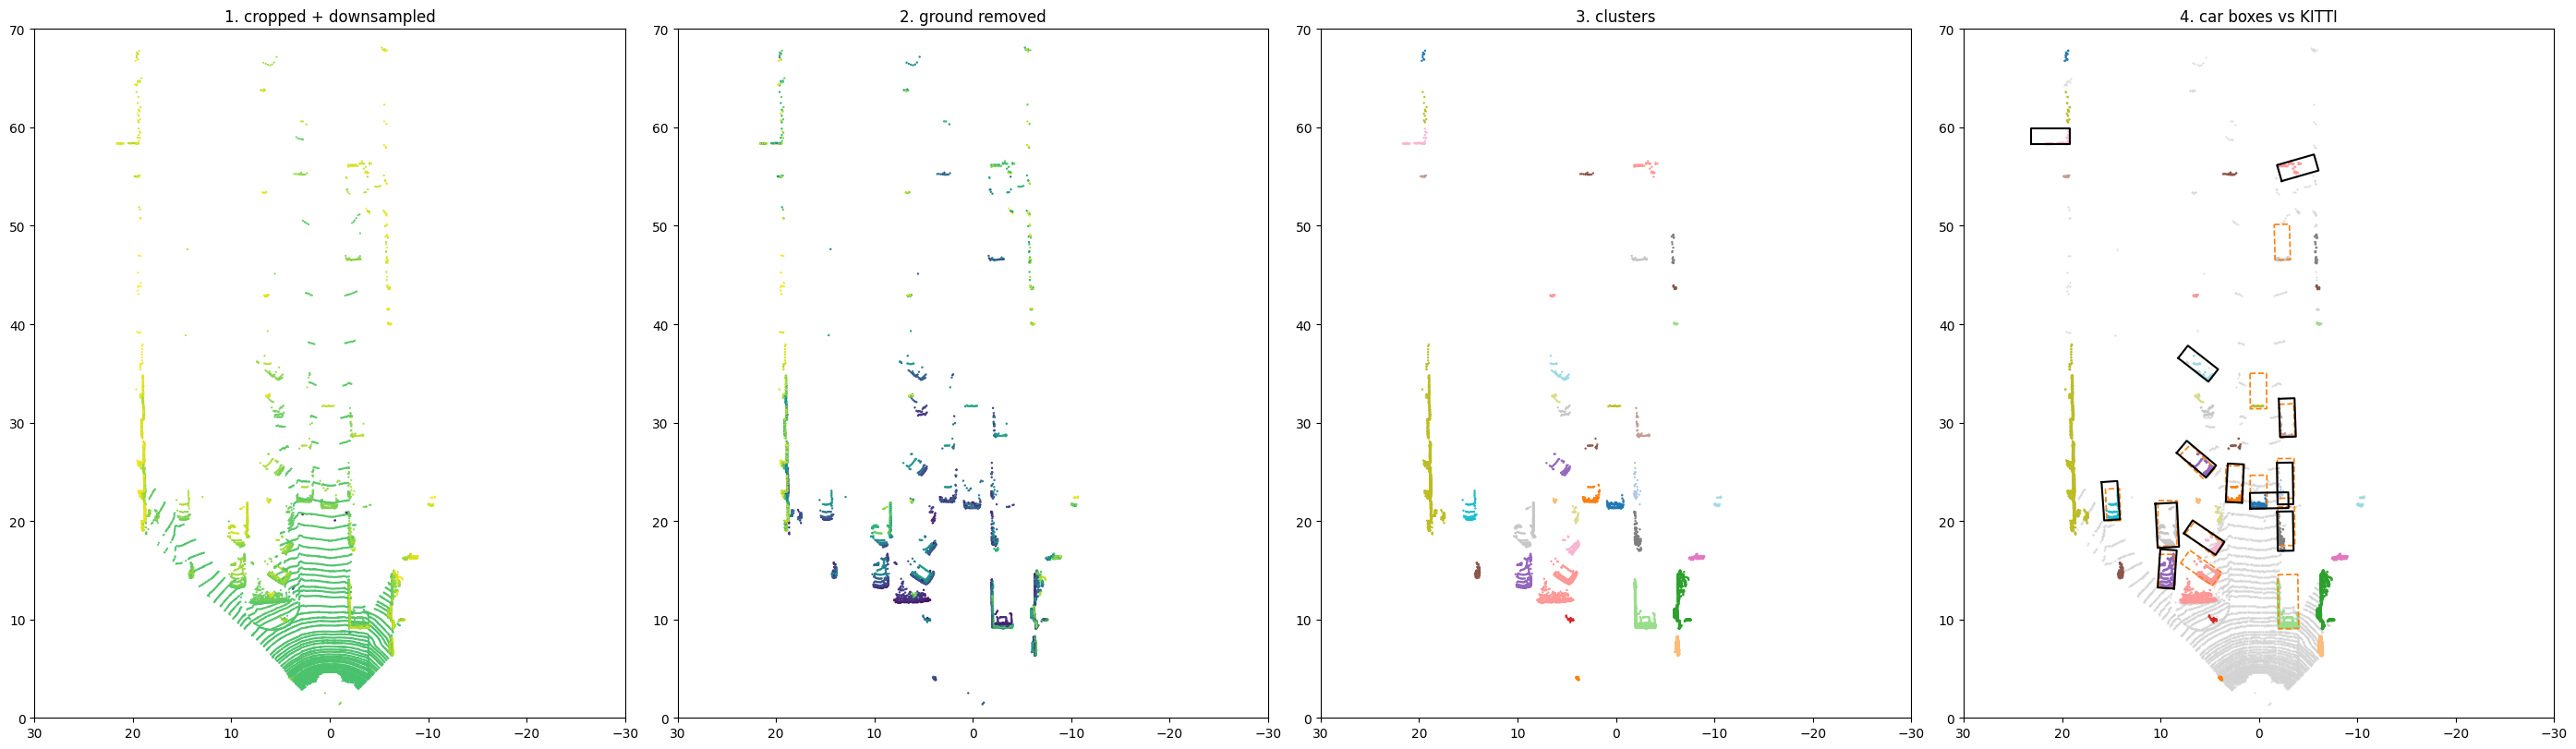

In [44]:
frame = val[40]
boxes, p, above, labels = predict(frame, CELL, debug=True)
fig, axes = plt.subplots(1, 4, figsize=(28, 8))
axes[0].scatter(p[:, 1], p[:, 0], s=0.3, c=p[:, 2], cmap="viridis")
axes[0].set_title("1. cropped + downsampled")
axes[1].scatter(above[:, 1], above[:, 0], s=0.5, c=above[:, 2], cmap="viridis")
axes[1].set_title("2. ground removed")
keep = labels >= 0
axes[2].scatter(above[keep, 1], above[keep, 0], s=0.5, c=labels[keep] % 20, cmap="tab20")
axes[2].set_title("3. clusters")
for ax in axes[:3]:
    ax.set(xlim=(30, -30), ylim=(0, 70), aspect="equal")
plot_result(frame, axes[3])
axes[3].set_title("4. car boxes vs KITTI")
plt.tight_layout()
plt.savefig(OUT / f"stages_{frame}.png", dpi=120)
plt.show()

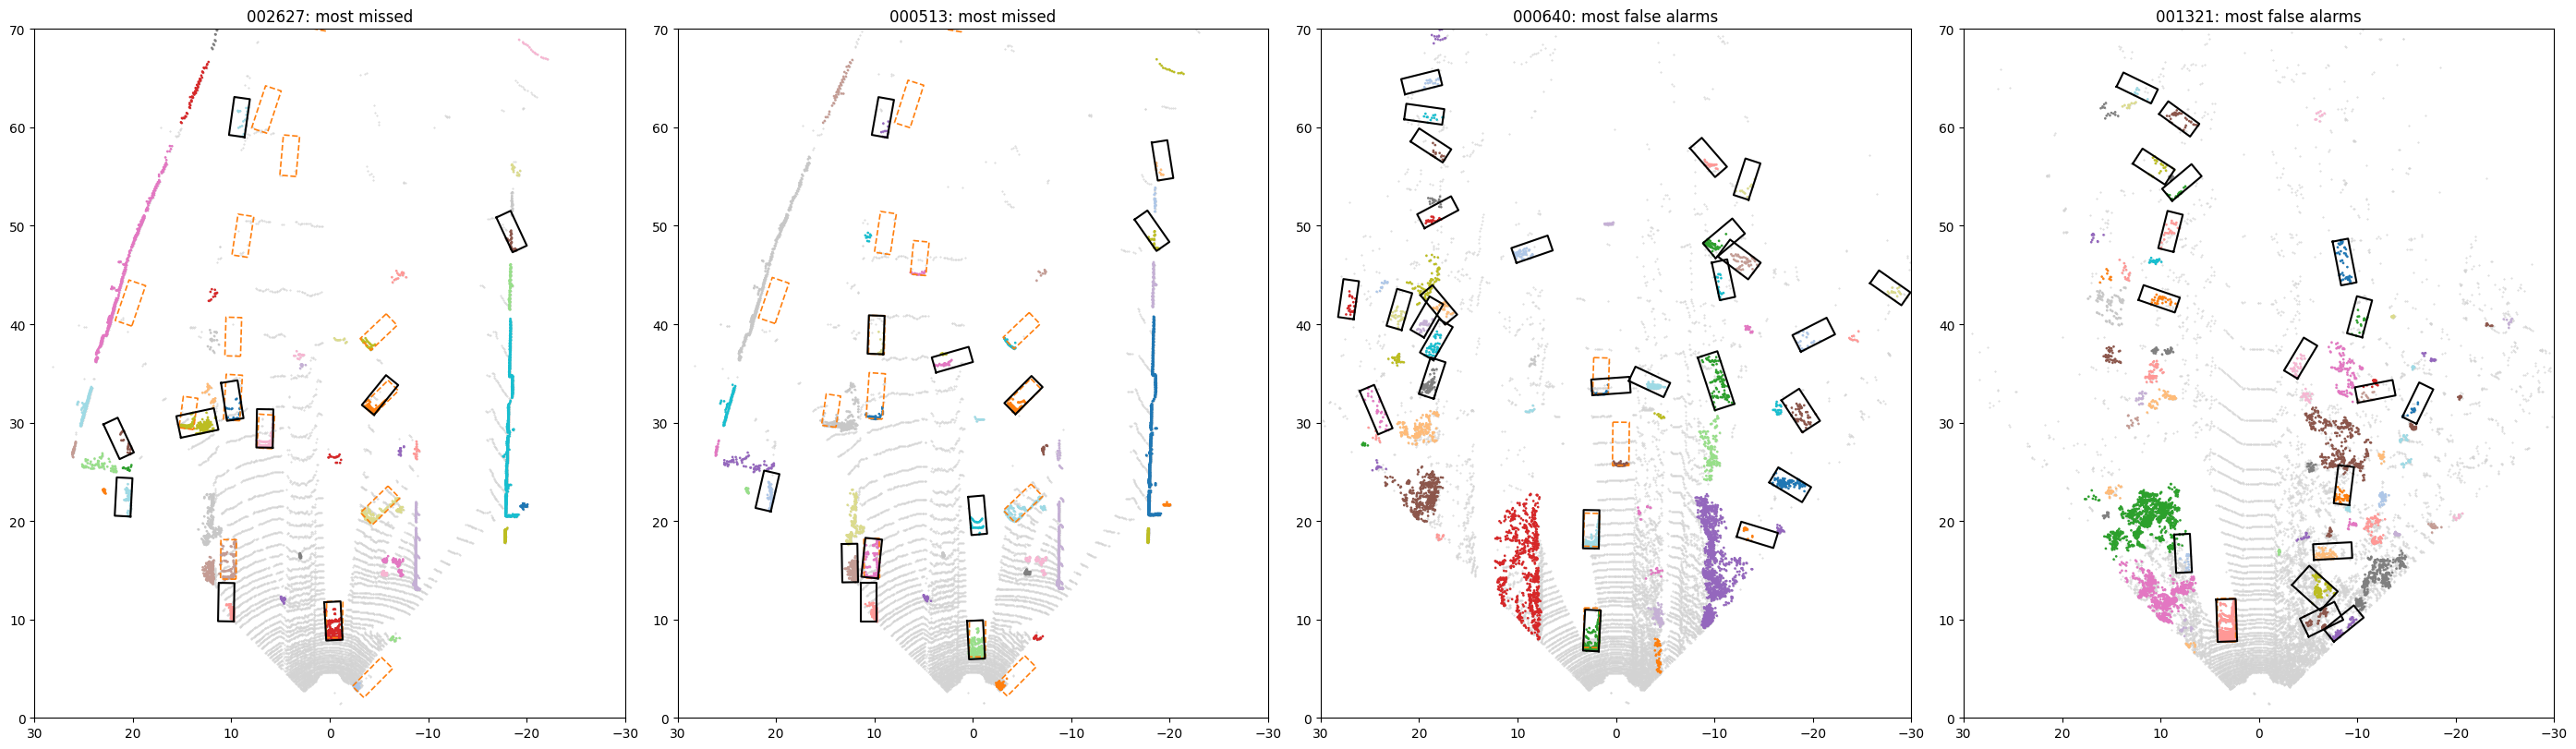

In [45]:

rows = []
for frame in val[:300]:
    ev = pd.DataFrame(score_frame(predict(frame, CELL), load_labels(frame, load_cam_to_velo(frame))),
                      columns=["type", "range", "iou"])
    rows.append({"frame": frame, "missed": (ev["type"] == "fn").sum(), "false alarms": (ev["type"] == "fp").sum()})
per_frame = pd.DataFrame(rows)
bad = per_frame.nlargest(2, "missed")["frame"].tolist() + per_frame.nlargest(2, "false alarms")["frame"].tolist()
fig, axes = plt.subplots(1, 4, figsize=(28, 8))
for f, ax, why in zip(bad, axes, ["most missed"] * 2 + ["most false alarms"] * 2):
    plot_result(f, ax)
    ax.set_title(f"{f}: {why}")
plt.tight_layout()
plt.savefig(OUT / "failures.png", dpi=120)
plt.show()